==================================================================
Air Quality Data Cleaning and Exploratory Data Analysis Pipeline - README
==================================================================

1. Libraries Imported:
   - numpy, pandas, seaborn, matplotlib.pyplot, yaml, os
   - Purpose: Data manipulation, plotting, configuration parsing, file handling

2. Load Configuration:
   - Reads 'config.yaml' to get paths for raw and processed data
   - raw_df_path: path to raw CSV
   - processed_path: path to save processed files

3. Load Raw Data:
   - raw_df = pd.read_csv(raw_df_path)
   - Renames columns for consistency:
       'Date' -> 'date', 'Time' -> 'time', 'CO_GT' -> 'co_ground_truth', etc.
   - Drops unneeded columns later:
       'nmhc_ground_truth', 'benzene_ground_truth', 'sensor_nmhc', 'sensor_o3'

4. Datetime Handling:
   - Combines 'date' and 'time' into a single 'datetime' column
   - Converts to datetime64[ns] type with dayfirst=True
   - Drops original 'date' and 'time' columns
   - Sorts DataFrame in ascending chronological order

5. Reorder Columns:
   - Moves 'datetime' to the first column for easier access

6. Separate Numeric and Non-Numeric Columns:
   - df_numeric: all numeric columns
   - df_non_numeric: all other columns

7. Data Cleaning:
   - Replace negative numeric values with NaN
   - Interpolate NaN values linearly (as an average of previous and next observation) along numeric columns
   - Recombine numeric and non-numeric columns into df_interpolated

8. Data Inspection:
   - df_interpolated.info(): check data types and non-null counts
   - df_interpolated.describe(): summary statistics

9. Plot Raw Data Overview:
   - Scatter plots for all columns vs datetime
   - Saved as 'raw_data_overview.png' in processed folder

10. Compute Time Differences:
    - df_interpolated['time_diff'] = difference between consecutive datetime entries
    - df_interpolated['time_diff_hours'] = time difference in hours

11. Encode CO Level Category:
    - Mapping: 'Very Low' -> 0.0, 'Low' -> 0.25, 'Moderate' -> 0.5, 'High' -> 0.75, 'Very High' -> 1.0
    - Adds new column: co_level_category_encoded

12. Create Time Index:
    - df_interpolated['time_index'] = 0,1,2,... after verifying 1-hour interval between measurements

13. Plot Distributions:
    - Histogram + KDE for all numeric columns excluding datetime, CO category, and time differences
    - Saved as 'raw_data_distributions.png' in processed folder

14. Create Clean Dataset:
    - Keep only relevant columns:
        'time_index', 'co_ground_truth', 'sensor_co', 'nox_ground_truth', 'sensor_nox',
        'no2_ground_truth', 'sensor_no2', 'temperature', 'relative_humidity', 'absolute_humidity'
    - Reorder so time_index is first
    - Save as 'cleaned_data.csv' in processed folder

15. Final Output:
    - df_clean: ready-to-use cleaned DataFrame
    - Contains numeric sensor data, meteorological data, and time_index for modeling

==================================================================


In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import yaml
import os
import matplotlib.pyplot as plt 

In [2]:
# Load config.yaml
import os
from pathlib import Path
# Config paths are relative to the repository root, so run from there whatever the notebook's own folder is
_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs" / "config.yaml").exists())
os.chdir(_ROOT)
with open('configs/config.yaml', 'r') as file:
    config = yaml.safe_load(file)

In [3]:
raw_df_path = config['data']['raw']
processed_path = config['data']['processed']

In [4]:
raw_df = pd.read_csv(raw_df_path)
raw_df.rename(columns={
    'Date': 'date',
    'Time': 'time',
    'CO_GT': 'co_ground_truth',
    'PT08_S1_CO': 'sensor_co',
    'NMHC_GT': 'nmhc_ground_truth',
    'C6H6_GT': 'benzene_ground_truth',
    'PT08_S2_NMHC': 'sensor_nmhc',
    'Nox_GT': 'nox_ground_truth',
    'PT08_S3_Nox': 'sensor_nox',
    'NO2_GT': 'no2_ground_truth',
    'PT08_S4_NO2': 'sensor_no2',
    'PT08_S5_O3': 'sensor_o3',
    'T': 'temperature',
    'RH': 'relative_humidity',
    'AH': 'absolute_humidity',
    'CO_level': 'co_level_category',
}, inplace=True)
    


In [5]:
raw_df

,date,time,co_ground_truth,sensor_co,nmhc_ground_truth,benzene_ground_truth,sensor_nmhc,nox_ground_truth,sensor_nox,no2_ground_truth,sensor_no2,sensor_o3,temperature,relative_humidity,absolute_humidity,co_level_category
0,11/23/2004,19:00:00,11.9,2008,-200,50.6,1980,1389,325,220,2562,2342,12.4,74.7,1.0741,Very High
1,11/23/2004,20:00:00,11.5,1918,-200,49.4,1958,1358,335,190,2477,2237,11.5,76.2,1.0324,Very High
2,11/17/2004,18:00:00,10.2,1802,-200,47.7,1924,748,356,192,2235,2452,13.7,52.8,0.8244,Very High
3,11/23/2004,18:00:00,10.2,1982,-200,49.5,1959,1369,322,227,2536,2386,13.2,72.6,1.0936,Very High
4,11/26/2004,18:00:00,10.1,1956,-200,45.2,1877,1389,347,255,2338,2465,15.5,62.8,1.0979,Very High
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9352,3/23/2005,4:00:00,-200.0,993,-200,2.3,604,85,848,65,1160,762,14.5,66.4,1.0919,Very low
9353,3/26/2005,4:00:00,-200.0,1122,-200,6.0,811,181,641,92,1336,1122,16.2,71.2,1.3013,Very low
9354,3/29/2005,4:00:00,-200.0,883,-200,1.3,530,63,997,46,1102,617,13.7,68.2,1.0611,Very low
9355,4/1/2005,4:00:00,-200.0,818,-200,0.8,473,47,1257,41,898,323,13.7,48.8,0.7606,Very low


In [6]:
raw_df['date'] = raw_df['date'].astype(str)
raw_df['time'] = raw_df['time'].astype(str)

# Combine and parse correctly, specifying the format if needed
raw_df['datetime'] = pd.to_datetime(raw_df['date'] + ' ' + raw_df['time'], dayfirst=True, errors='coerce')
raw_df.drop(columns=['date', 'time'], inplace=True)
raw_df.drop(columns=['nmhc_ground_truth', 'benzene_ground_truth', 'sensor_nmhc', 'sensor_o3'], inplace=True)

# Now sort
raw_df = raw_df.sort_values('datetime').reset_index(drop=True)


C:\Users\Rihan\AppData\Local\Temp\ipykernel_33516\1243519803.py:5: UserWarning: Parsing dates in %m/%d/%Y %H:%M:%S format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  raw_df['datetime'] = pd.to_datetime(raw_df['date'] + ' ' + raw_df['time'], dayfirst=True, errors='coerce')


In [7]:
raw_df

,co_ground_truth,sensor_co,nox_ground_truth,sensor_nox,no2_ground_truth,sensor_no2,temperature,relative_humidity,absolute_humidity,co_level_category,datetime
0,2.6,1360,166,1056,113,1692,13.6,48.9,0.7578,High,2004-03-10 18:00:00
1,2.0,1292,103,1174,92,1559,13.3,47.7,0.7255,High,2004-03-10 19:00:00
2,2.2,1402,131,1140,114,1555,11.9,54.0,0.7502,High,2004-03-10 20:00:00
3,2.2,1376,172,1092,122,1584,11.0,60.0,0.7867,High,2004-03-10 21:00:00
4,1.6,1272,131,1205,116,1490,11.2,59.6,0.7888,High,2004-03-10 22:00:00
...,...,...,...,...,...,...,...,...,...,...,...
9352,3.1,1314,472,539,190,1374,21.9,29.3,0.7568,High,2005-04-04 10:00:00
9353,2.4,1163,353,604,179,1264,24.3,23.7,0.7119,High,2005-04-04 11:00:00
9354,2.4,1142,293,603,175,1241,26.9,18.3,0.6406,High,2005-04-04 12:00:00
9355,2.1,1003,235,702,156,1041,28.3,13.5,0.5139,High,2005-04-04 13:00:00


In [8]:
cols = raw_df.columns.tolist()
cols.insert(0, cols.pop(cols.index('datetime')))
df = raw_df[cols]
df.columns, df.shape

(Index(['datetime', 'co_ground_truth', 'sensor_co', 'nox_ground_truth',
        'sensor_nox', 'no2_ground_truth', 'sensor_no2', 'temperature',
        'relative_humidity', 'absolute_humidity', 'co_level_category'],
       dtype='object'),
 (9357, 11))

In [9]:
df_numeric = df.select_dtypes(include=[np.number])
df_non_numeric = df.select_dtypes(exclude=[np.number])

# Replace negative values with NaN
df_numeric = df_numeric.mask(df_numeric < 0)

# Interpolate NaNs linearly in numeric columns only
df_numeric_interpolated = df_numeric.interpolate(method='linear', limit_direction='both')

# Combine numeric and non-numeric columns back
df_interpolated = pd.concat([df_non_numeric, df_numeric_interpolated], axis=1)
df_interpolated.shape


(9357, 11)

In [10]:
df_interpolated.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9357 entries, 0 to 9356
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   datetime           9357 non-null   datetime64[ns]
 1   co_level_category  9357 non-null   object        
 2   co_ground_truth    9357 non-null   float64       
 3   sensor_co          9357 non-null   float64       
 4   nox_ground_truth   9357 non-null   float64       
 5   sensor_nox         9357 non-null   float64       
 6   no2_ground_truth   9357 non-null   float64       
 7   sensor_no2         9357 non-null   float64       
 8   temperature        9357 non-null   float64       
 9   relative_humidity  9357 non-null   float64       
 10  absolute_humidity  9357 non-null   float64       
dtypes: datetime64[ns](1), float64(9), object(1)
memory usage: 804.2+ KB


In [11]:
df_interpolated.describe()

,datetime,co_ground_truth,sensor_co,nox_ground_truth,sensor_nox,no2_ground_truth,sensor_no2,temperature,relative_humidity,absolute_humidity
count,9357,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000
mean,2004-09-21 16:00:00,2.130603,1103.059741,241.922197,832.758897,109.632094,1453.298814,18.236694,49.191386,1.019621
min,2004-03-10 18:00:00,0.100000,647.000000,2.000000,322.000000,2.000000,551.000000,0.000000,9.200000,0.184700
25%,2004-06-16 05:00:00,1.100000,938.000000,96.000000,654.000000,76.000000,1227.000000,11.700000,35.800000,0.732300
50%,2004-09-21 16:00:00,1.800000,1067.000000,180.000000,804.000000,104.917526,1460.000000,17.600000,49.600000,0.989500
75%,2004-12-28 03:00:00,2.900000,1239.000000,326.000000,968.000000,136.314685,1668.000000,24.300000,62.300000,1.306700
max,2005-04-04 14:00:00,11.900000,2040.000000,1479.000000,2683.000000,340.000000,2775.000000,44.600000,88.700000,2.231000
std,NaN,1.431736,218.196346,204.315075,255.709833,46.462311,343.206131,8.775215,17.194506,0.402203


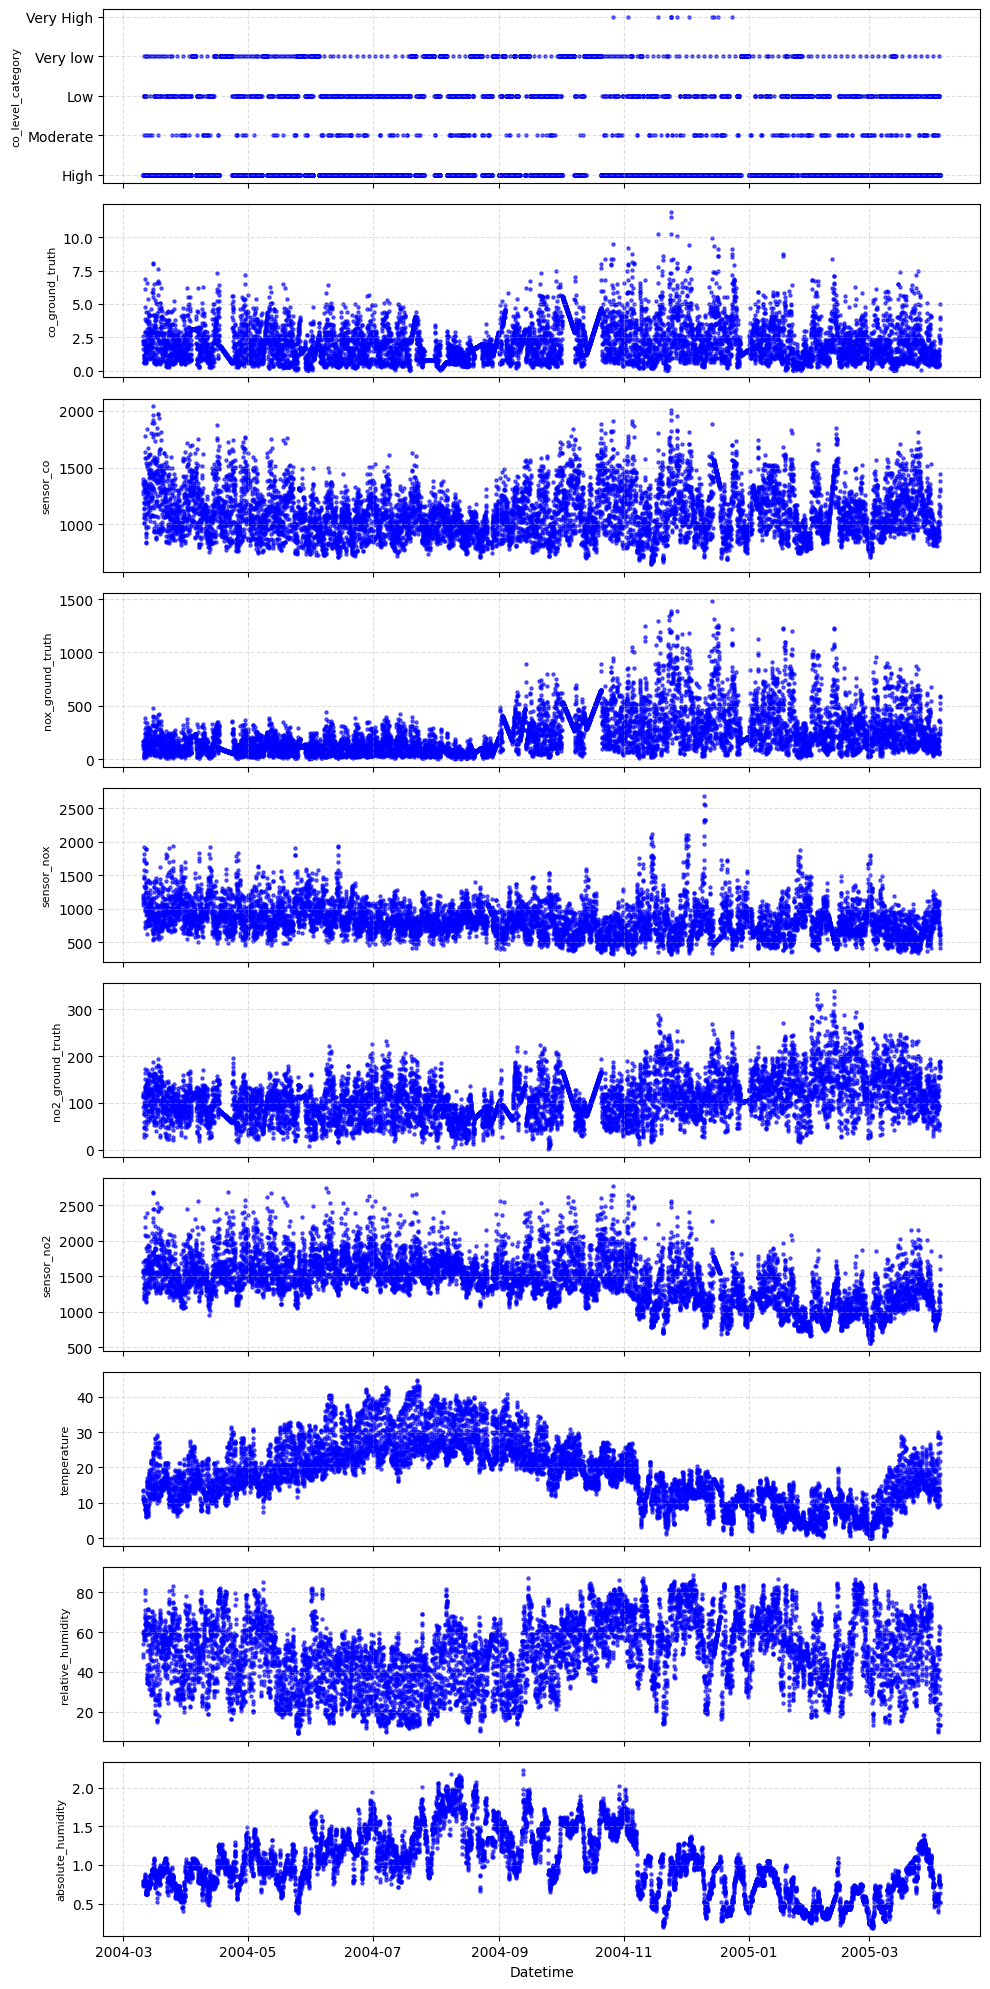

In [12]:
# Assuming df_interpolated is your DataFrame
cols_to_plot = df_interpolated.columns.drop('datetime')

# Create subplots
fig, axes = plt.subplots(len(cols_to_plot), 1, figsize=(10, len(cols_to_plot)*2), sharex=True)

# Loop through columns and plot
for i, col in enumerate(cols_to_plot):
    axes[i].scatter(df_interpolated['datetime'], df_interpolated[col], s=5, color='blue', alpha=0.6)
    axes[i].set_ylabel(col, fontsize=8)
    axes[i].grid(True, linestyle='--', alpha=0.4)

axes[-1].set_xlabel('Datetime')
plt.tight_layout()
plt.savefig(os.path.join(processed_path, 'raw_data_overview.png'), dpi=300)
plt.show()

In [13]:
df_interpolated['time_diff'] = df_interpolated['datetime'].diff()
df_interpolated['time_diff_hours'] = df_interpolated['time_diff'].dt.total_seconds() / 3600

co_level_mapping = {
    'Very Low': 0.0,
    'Low': 0.25,
    'Moderate': 0.5,
    'High': 0.75,
    'Very High': 1.0
}

# Apply mapping
df_interpolated['co_level_category_encoded'] = df_interpolated['co_level_category'].map(co_level_mapping)
df_interpolated['time_index'] = range(len(df_interpolated))



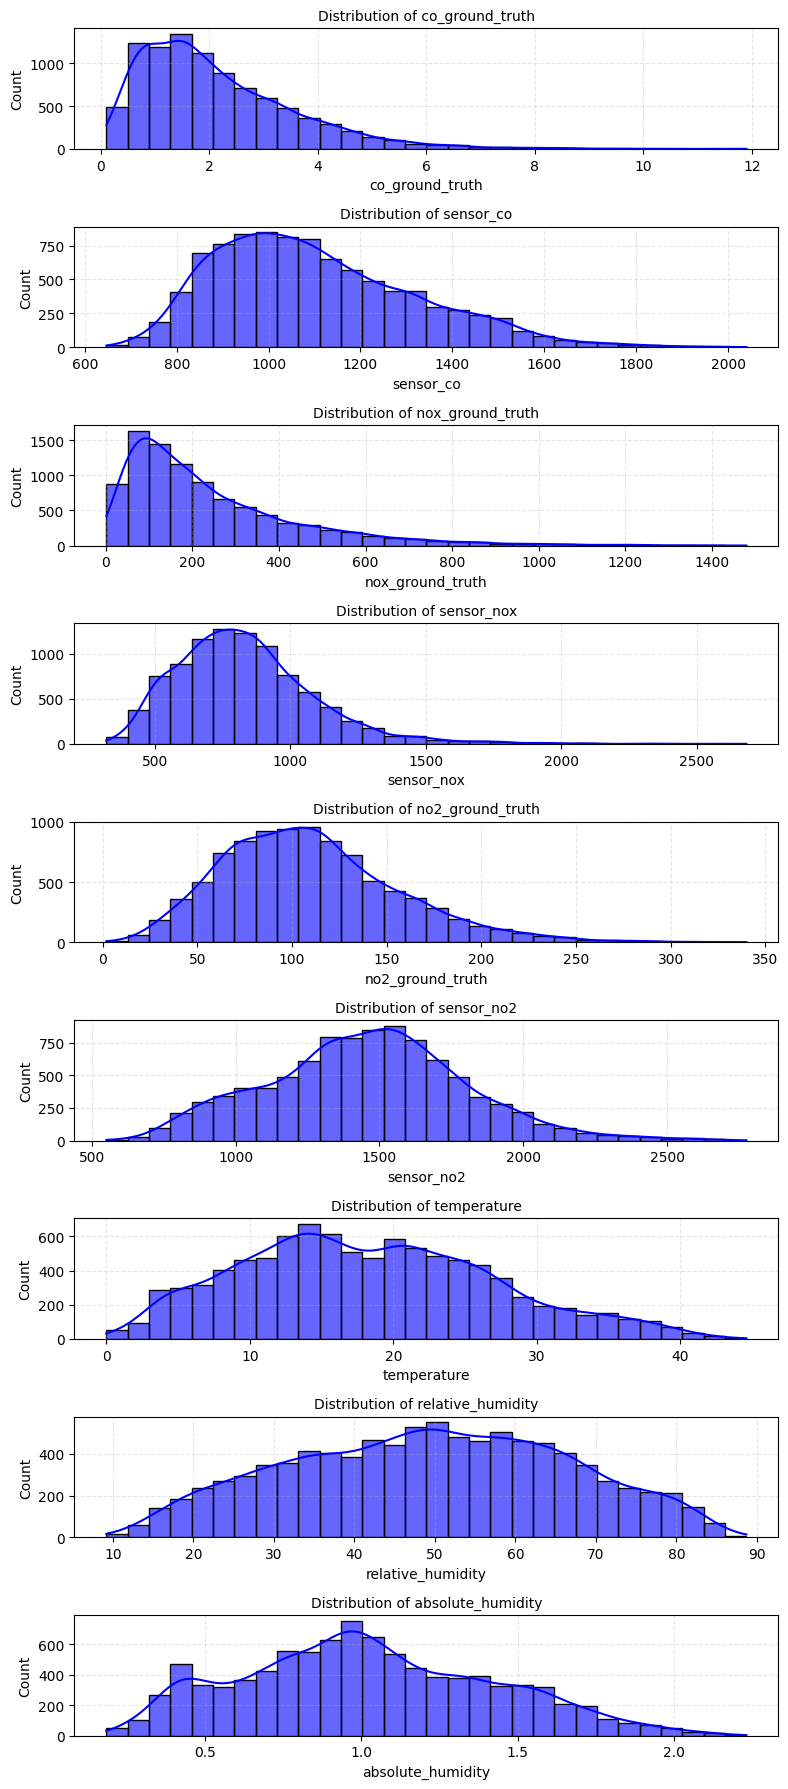

In [14]:
# Columns to plot
cols_to_plot = df_interpolated.columns.drop(['datetime', 'co_level_category_encoded', 'co_level_category', 'time_diff', 'time_diff_hours', 'time_index'])

# Create subplots
fig, axes = plt.subplots(len(cols_to_plot), 1, figsize=(8, len(cols_to_plot)*2))

# Loop through columns and plot distributions
for i, col in enumerate(cols_to_plot):
    sns.histplot(df_interpolated[col], kde=True, ax=axes[i], bins=30, color='blue', alpha=0.6)
    axes[i].set_title(f'Distribution of {col}', fontsize=10)
    axes[i].grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(processed_path, 'raw_data_distributions.png'), dpi=300)
plt.show()


In [15]:
df_interpolated.columns

Index(['datetime', 'co_level_category', 'co_ground_truth', 'sensor_co',
       'nox_ground_truth', 'sensor_nox', 'no2_ground_truth', 'sensor_no2',
       'temperature', 'relative_humidity', 'absolute_humidity', 'time_diff',
       'time_diff_hours', 'co_level_category_encoded', 'time_index'],
      dtype='object')

In [16]:
# List of columns to keep
cols_to_keep = [
    'time_index',  # keep first
    'co_ground_truth', 'sensor_co',
    'nox_ground_truth', 'sensor_nox',
    'no2_ground_truth', 'sensor_no2',
    'temperature', 'relative_humidity', 'absolute_humidity',
]

# Select and reorder columns
df_clean = df_interpolated[cols_to_keep].copy()

# Check the result
df_clean.shape


(9357, 10)

In [17]:
df_clean.to_csv(os.path.join(processed_path, 'cleaned_data.csv'), index=False)


In [18]:
df_clean

,time_index,co_ground_truth,sensor_co,nox_ground_truth,sensor_nox,no2_ground_truth,sensor_no2,temperature,relative_humidity,absolute_humidity
0,0,2.6,1360.0,166.0,1056.0,113.0,1692.0,13.6,48.9,0.7578
1,1,2.0,1292.0,103.0,1174.0,92.0,1559.0,13.3,47.7,0.7255
2,2,2.2,1402.0,131.0,1140.0,114.0,1555.0,11.9,54.0,0.7502
3,3,2.2,1376.0,172.0,1092.0,122.0,1584.0,11.0,60.0,0.7867
4,4,1.6,1272.0,131.0,1205.0,116.0,1490.0,11.2,59.6,0.7888
...,...,...,...,...,...,...,...,...,...,...
9352,9352,3.1,1314.0,472.0,539.0,190.0,1374.0,21.9,29.3,0.7568
9353,9353,2.4,1163.0,353.0,604.0,179.0,1264.0,24.3,23.7,0.7119
9354,9354,2.4,1142.0,293.0,603.0,175.0,1241.0,26.9,18.3,0.6406
9355,9355,2.1,1003.0,235.0,702.0,156.0,1041.0,28.3,13.5,0.5139
